### 1. Significant earthquakes since 2150 B.C.

The Significant Earthquake Database contains information on destructive earthquakes from 2150 B.C. to the present. On the top left corner, select all columns and download the entire significant earthquake data file in .tsv format by clicking the Download TSV File button. Click the variable name for more information. Read the file (e.g., earthquakes-2026-10-14_11-23-28_+0800.tsv) as an object and name it Sig_Eqs.

1.1 Compute the total number of deaths caused by earthquakes since 2150 B.C. in each country, and then print the top 20 countries along with the total number of deaths.

In [1]:
import pandas as pd

In [2]:
file1 = 'D:/SUST/ESE/Assignment/Assignment2/earthquakes-2026-10-14_20-30-56_+0800.tsv'
Sig_Eqs = pd.read_csv(file1, sep="\t", skiprows=[1])

In [3]:
Sig_Eqs["Total Deaths"] = pd.to_numeric(Sig_Eqs["Total Deaths"], errors="coerce")     #计算死亡数

grouped = Sig_Eqs.groupby('Country')['Total Deaths'].sum()
sorted_data = grouped.sort_values(ascending=False)     #按国家分类排序
top20 = sorted_data.head(20)

print(top20.to_string())

Country
CHINA           2106526.0
TURKEY          1008867.0
IRAN             761656.0
SYRIA            488326.0
ITALY            417297.0
HAITI            323782.0
JAPAN            319510.0
AZERBAIJAN       319251.0
INDONESIA        283485.0
ARMENIA          175000.0
PAKISTAN         143714.0
ECUADOR          134445.0
TURKMENISTAN     110412.0
PERU              97009.0
GREECE            83658.0
PORTUGAL          82572.0
IRAQ              70200.0
CHILE             70175.0
INDIA             63413.0
ISRAEL            58368.0


1.2 Compute the total number of earthquakes with magnitude larger than 3.0 (use column Ms as the magnitude) worldwide each year, and then plot the time series. Do you observe any trend? Explain why or why not?

In [4]:
import matplotlib.pyplot as plt

In [5]:
Sig_Eqs["Ms"] = pd.to_numeric(Sig_Eqs["Ms"], errors="coerce")

big_eqs = Sig_Eqs[Sig_Eqs["Ms"] > 3.0]     # 筛选震级大于3.0的地震

yearly_count = big_eqs.groupby("Year").size()     #按年份分组

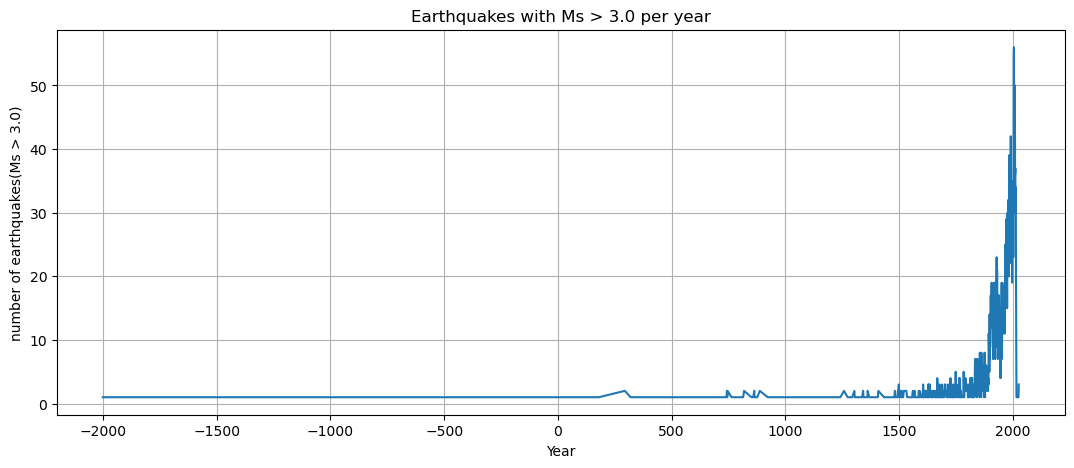

In [6]:
fig = plt.figure(figsize=(13,5))
plt.plot(yearly_count.index, yearly_count.values)
plt.xlabel('Year')
plt.ylabel('number of earthquakes(Ms > 3.0)')
plt.title('Earthquakes with Ms > 3.0 per year')
plt.grid()
plt.show()     #画图

近代1900年后震级大于3.0的地震数量大幅上升，在此之前地震数量波动平稳并维持在一个较低的数值。

近现代随着科技的发展，对地震及震级的检测更为精确，因此记录的地震数量大幅上升。古代只有震级极大破坏性极强的地震会被记录。

1.3 Write a function CountEq_LargestEq that returns (a) the total number of earthquakes since 2150 B.C. in a given country AND (b) date and location of the largest earthquake ever happened in this country. Apply CountEq_LargestEq to every country in the file, report your results in a descending order.

In [7]:
def CountEq_LargestEq(country):
    df = Sig_Eqs[Sig_Eqs["Country"] == country]
    total_count = len(df)     # (a) 计算地震总数
    
    # 清洗数据
    df_mag = pd.to_numeric(df["Mag"], errors="coerce")
    
    # 若某国的 Mag 为空值
    if df_mag.isna().all():
        return total_count, "No Mag Data", "No Location"
    
    largest_row = df.loc[df_mag.idxmax()]
    year = int(largest_row["Year"])      # (b) 找最大地震
    
    if year < 0:
        date_str = f"{-year} B.C."
    else:
        date_str = f"{year} A.D."
        
    location = largest_row["Location Name"]
    
    return total_count, date_str, location

In [8]:
countries = Sig_Eqs["Country"].dropna().unique()
results = []

for country in countries:
    total, date, location = CountEq_LargestEq(country)
    results.append((country, total, date, location))

# 按地震总数降序排序
results.sort(key=lambda x: x[1], reverse=True)

for country, total, date, location in results:
    print(country, "| 总数:", total, "| 日期:", date, "| 地点:", location)

CHINA | 总数: 626 | 日期: 1668 A.D. | 地点: CHINA:  SHANDONG PROVINCE
JAPAN | 总数: 429 | 日期: 2011 A.D. | 地点: JAPAN:  HONSHU
INDONESIA | 总数: 427 | 日期: 2004 A.D. | 地点: INDONESIA:  SUMATRA:  ACEH:  OFF WEST COAST
IRAN | 总数: 385 | 日期: 856 A.D. | 地点: IRAN:  DAMGHAN, QUMIS
TURKEY | 总数: 359 | 日期: 1939 A.D. | 地点: TURKEY:  ERZINCAN
ITALY | 总数: 338 | 日期: 1915 A.D. | 地点: ITALY:  MARSICA, AVEZZANO, ABRUZZI
GREECE | 总数: 296 | 日期: 365 A.D. | 地点: GREECE:  CRETE:  KNOSSOS
USA | 总数: 283 | 日期: 1964 A.D. | 地点: ALASKA
PHILIPPINES | 总数: 233 | 日期: 1897 A.D. | 地点: PHILIPPINES:  MINDANAO, ZAMBOANGA, SULU, ISABELA
MEXICO | 总数: 217 | 日期: 1787 A.D. | 地点: MEXICO:  SAN MARCOS, OAXACA
CHILE | 总数: 200 | 日期: 1960 A.D. | 地点: CHILE:  PUERTO MONTT, VALDIVIA
PERU | 总数: 195 | 日期: 1716 A.D. | 地点: PERU:  PUEBLO DE TORATA IN TACNA
RUSSIA | 总数: 159 | 日期: 1952 A.D. | 地点: RUSSIA:  KAMCHATKA PENINSULA
PAPUA NEW GUINEA | 总数: 107 | 日期: 1919 A.D. | 地点: PAPUA NEW GUINEA:  SOLOMON ISLANDS
TAIWAN | 总数: 103 | 日期: 1920 A.D. | 地点: TAIWAN
INDIA 

### 2. Air temperature in Shenzhen 1998-2022

In this problem set, we will examine how air temperature changes in Shenzhen from 1998 to 2022 using the hourly weather data measured at the Baoan International Airport. The data set is from NOAA Integrated Surface Dataset. Download the zipped file Baoan_Weather_1998_2022.zip, unzip it, and move the Baoan_Weather_1998_2022.csv file to your working directory.  
Read page 10-11 (POS 88-92 and POS 93-93) of the comprehensive user guide for the detailed format of the air temperature data (use column TMP). Explain how you filter the data in your report.  
Plot monthly averaged air temperature against the observation time. Is there a trend in monthly averaged air temperature from 1998 to 2022?

根据 NOAA ISD 用户手册，TMP 列格式为“数值,质量码”，其中 POS 88–92 是以 0.1°C 为单位、带正负号的气温值（如 +0164 表示 16.4°C），POS 93 是质量控制码（1 表示通过全部检查，0 表示数值有效但未通过部分检查，2–9 为各类错误或缺失码）。在过滤时，我先剔除 TMP 为空、或数值为缺失哨兵 ±9999 的记录，再只保留质量码为 1 的记录，然后将原始值除以 10 转换为摄氏度；由于 CSV 中存在重复的 CALL_SIGN 和 QUALITY_CONTROL 列，我按列名精确读取 TMP 字段以避免列错位，最后将逐小时有效气温按日历月聚合为月平均气温并绘图。

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [10]:
df = pd.read_csv(
    "D:\SUST\ESE\Assignment\Assignment2\Baoan_Weather_1998_2022.csv",
    dtype=str,
    keep_default_na=False
)

In [11]:
df['DATE_parsed'] = pd.to_datetime(df['DATE'], errors='coerce')
df = df.dropna(subset=['DATE_parsed']).copy()     # 时间解析

# 温度TEM
def parse_tmp(raw):
    if raw is None:
        return np.nan, np.nan
    raw = str(raw).strip()
    if raw == '' or raw.lower() == 'nan':
        return np.nan, np.nan
    parts = raw.split(',')
    if len(parts) < 1:
        return np.nan, np.nan

    val_str = parts[0].strip()
    qc_str  = parts[1].strip() if len(parts) > 1 else ''

    num_part = val_str.lstrip('+-')
    if num_part != '' and num_part.isdigit():
        val = float(val_str)
    else:
        return np.nan, np.nan
    if abs(val) >= 9999:          # ±9999 缺失
        return np.nan, np.nan
    temp_c = val / 10.0

    # 质量码
    qc_part = qc_str.lstrip('+-')
    if qc_part != '' and qc_part.isdigit():
        qc = int(qc_str)
    else:
        qc = np.nan
    return temp_c, qc

tmp_parsed = df['TMP'].apply(parse_tmp)
df['TMP_C']  = [x[0] for x in tmp_parsed]
df['TMP_QC'] = [x[1] for x in tmp_parsed]

# 保留 QC==1
mask_valid = (df['TMP_QC'] == 1) & df['TMP_C'].notna()
df_valid = df.loc[mask_valid, ['DATE_parsed', 'TMP_C']].copy()

# 计算月平均值
df_valid['YearMonth'] = df_valid['DATE_parsed'].dt.to_period('M')
monthly = (df_valid
           .groupby('YearMonth')['TMP_C']
           .agg(['mean', 'count'])
           .reset_index())
monthly['date'] = monthly['YearMonth'].dt.to_timestamp()
monthly = monthly[monthly['count'] >= 50].copy()

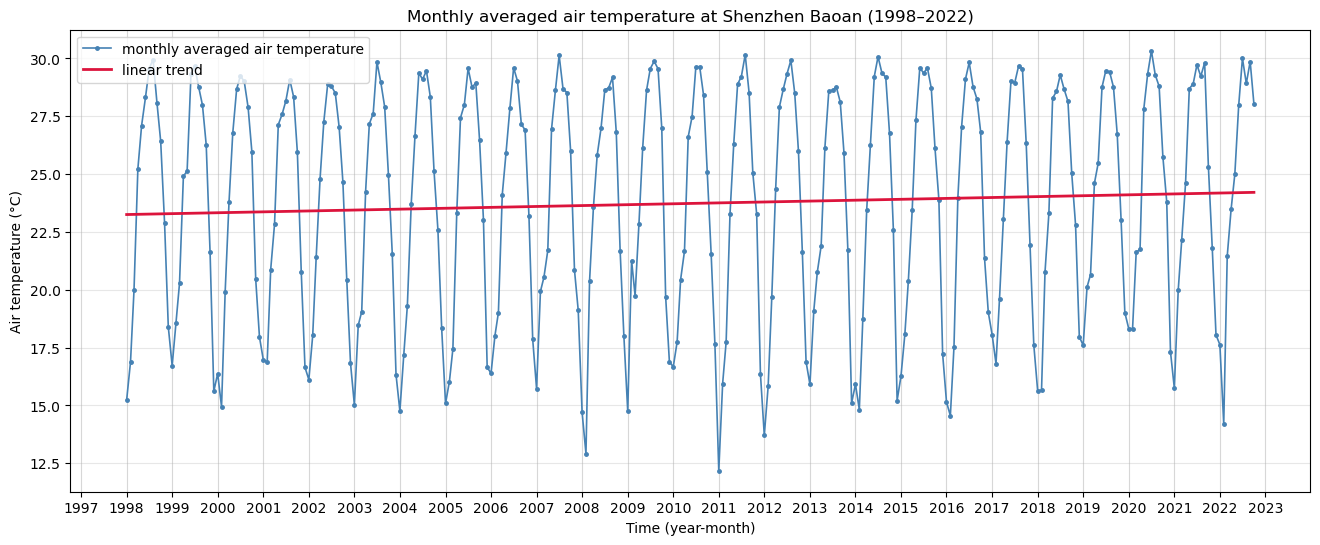

In [12]:
# 作图
fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(monthly['date'], monthly['mean'],
        color='steelblue', lw=1.2, marker='o', ms=2.5,
        label='monthly averaged air temperature')

# 趋势线
x_num = mdates.date2num(monthly['date'])
if len(monthly) >= 2:
    coef = np.polyfit(x_num, monthly['mean'], 1)
    ax.plot(monthly['date'], np.polyval(coef, x_num),
            color='crimson', lw=2,
            label='linear trend')

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

ax.grid(which='major', axis='x', alpha=0.5, linestyle='-')
ax.grid(which='minor', axis='x', alpha=0.3, linestyle=':') 
ax.grid(which='major', axis='y', alpha=0.3, linestyle='-')

ax.set_xlabel('Time (year-month)')
ax.set_ylabel('Air temperature (°C)')
ax.set_title('Monthly averaged air temperature at Shenzhen Baoan (1998–2022)')
ax.legend(loc='upper left')

plt.show()

对 1998–2022 年深圳宝安月平均气温序列的分析表明，月平均气温呈现强烈的季节性周期：7–8 月最高（约 28–30°C），1–2 月最低（约 13–16°C）；气温存在明显的上升（变暖）趋势：序列虽以强烈的季节性周期为主，但周期之上基线整体上移，冬季低谷的抬升尤为明显。

### 3. Global collection of hurricanes

The International Best Track Archive for Climate Stewardship (IBTrACS) project is the most complete global collection of tropical cyclones available. It merges recent and historical tropical cyclone data from multiple agencies to create a unified, publicly available, best-track dataset that improves inter-agency comparisons. IBTrACS was developed collaboratively with all the World Meteorological Organization (WMO) Regional Specialized Meteorological Centers, as well as other organizations and individuals from around the world.  
In this problem set, we will use all storms available in the IBTrACS record since 1842. Download the zipped file ibtracs.ALL.list.v04r00.zip, unzip it, and move the ibtracs.ALL.list.v04r00.csv file to your working directory. Read Column Variable Descriptions for variables in the file. Examine the first few lines of the file.

3.1 Group the data on Storm Identifie (SID), report names (NAME) of the 10 largest hurricanes according to wind speed (WMO_WIND).

In [13]:
import pandas as pd

In [14]:
df = pd.read_csv('D:/SUST/ESE/Assignment/Assignment2/ibtracs.ALL.list.v04r00.csv',
                 usecols=range(17),
                 skiprows=[1, 2], 
                 parse_dates=['ISO_TIME'],
                 na_values=['NOT_NAMED', 'NAME'],
                 low_memory=False)      # 读取数据 

In [15]:
df_sorted = df.sort_values(by=['SID', 'WMO_WIND'], ascending=[True, False])     # 按 SID 和 WMO_WIND 降序排列

storm_summary = df_sorted.drop_duplicates(subset=['SID'], keep='first')

top_10_storms = storm_summary.sort_values(by='WMO_WIND', ascending=False).head(10)     # 取前10名

print("10个最大飓风的名称（按WMO_WIND排序）：")
print(top_10_storms[['NAME', 'WMO_WIND']].to_string(index=False))

10个最大飓风的名称（按WMO_WIND排序）：
          NAME WMO_WIND
        RHONDA       95
         TALIM       95
         PERCY       95
        INGRID       95
ADELINE:JULIET       95
         NESAT       95
         EMILY       95
       HAITANG       95
         MAWAR       95
       KATRINA       95


3.2 List the wind speed (WMO_WIND) of the 20 strongest-wind hurricanes.

In [16]:
top_20_storms = storm_summary.sort_values(by='WMO_WIND', ascending=False)     # 按最大风速降序排列

top_20_wind_speeds = top_20_storms['WMO_WIND'].head(20)     # 提取前 20 名的风速

print("20个最强飓风的风速 (WMO_WIND)：")
print(top_20_wind_speeds.to_string(index=False))

20个最强飓风的风速 (WMO_WIND)：
95
95
95
95
95
95
95
95
95
95
95
95
95
95
95
95
95
95
95
95


3.3 Count all datapoints by Basin.

In [17]:
basin_counts = df['BASIN'].value_counts()     # 统计各 BASIN 的数据点数量

print("各BASIN的数据点数量:")
print(basin_counts)

各BASIN的数据点数量:
BASIN
WP    236576
SI    160668
SP     67119
EP     62412
NI     55401
SA       119
Name: count, dtype: int64


3.4 Make a hexbin plot of the location of datapoints in Latitude and Longitude.

In [18]:
import matplotlib.pyplot as plt

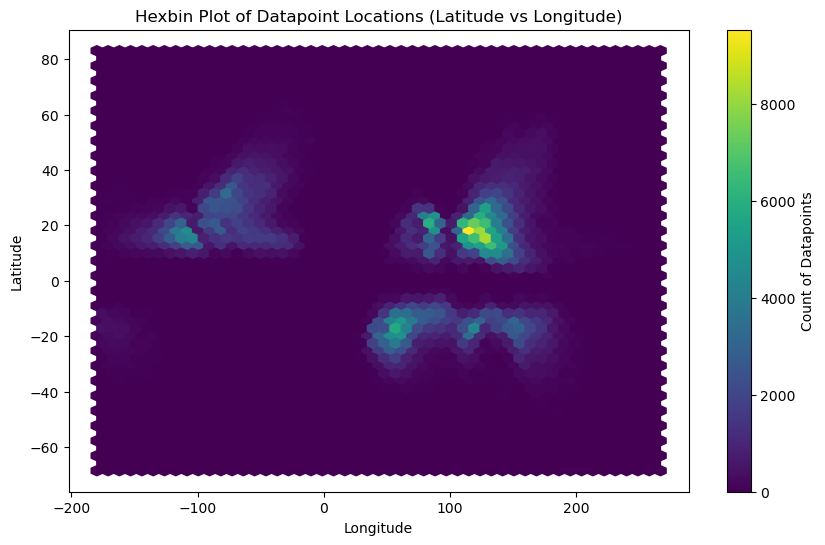

In [19]:
plt.figure(figsize=(10, 6))
plt.hexbin(df['LON'], df['LAT'], gridsize=50, cmap='viridis')     # 提取 LON 作为 X 轴，LAT 作为 Y 轴
plt.colorbar(label='Count of Datapoints')
plt.xlabel('Longitude') 
plt.ylabel('Latitude') 
plt.title('Hexbin Plot of Datapoint Locations (Latitude vs Longitude)')

plt.show()

3.5 Find Typhoon Mangkhut (from 2018) and plot its track.

In [20]:
mangkhut_data = df[(df['NAME'].str.contains('MANGKHUT', case=False, na=False)) & 
                   (df['ISO_TIME'].dt.year == 2018)]     # 筛选数据：名称包含 MANGKHUT 且年份为 2018

mangkhut_data = mangkhut_data.sort_values(by='ISO_TIME')     # 按时间排序

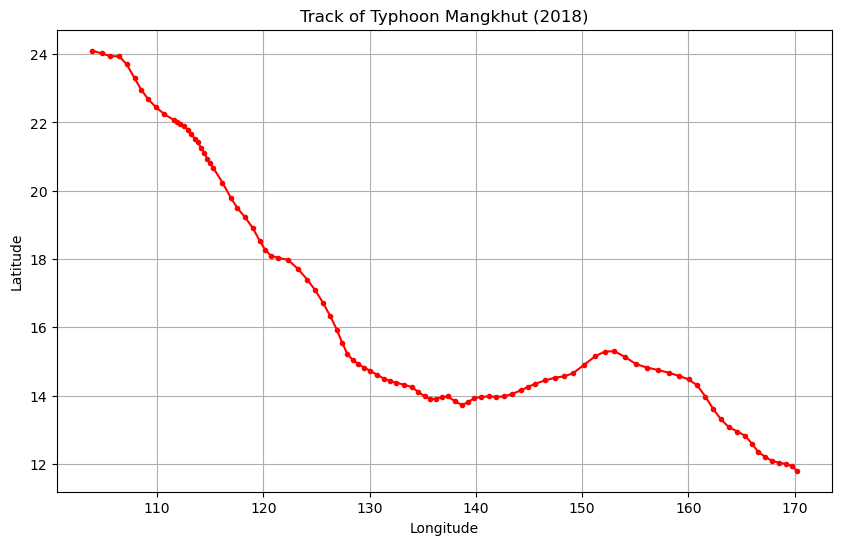

In [21]:
# 绘图
plt.figure(figsize=(10, 6))
plt.plot(mangkhut_data['LON'], mangkhut_data['LAT'], marker='o', markersize=3, linestyle='-', color='red')

plt.title('Track of Typhoon Mangkhut (2018)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid()

plt.show()

3.6 Create a filtered dataframe that contains only data since 1970 from the Western North Pacific (“WP”) and Eastern North Pacific (“EP”) Basin. Use this for the rest of the problem set.

In [22]:
df_filtered = df[(df['ISO_TIME'].dt.year >= 1970) & 
                 (df['BASIN'].isin(['WP', 'EP']))].copy()     # 提取年份大于等于 1970，并且 BASIN 属于 'WP' 或 'EP'

3.7 Plot the number of datapoints per day.

In [23]:
df_filtered['date'] = df_filtered['ISO_TIME'].dt.date     # 提取日期

daily_counts = df_filtered.groupby('date').size()     # 统计每天的数据点个数

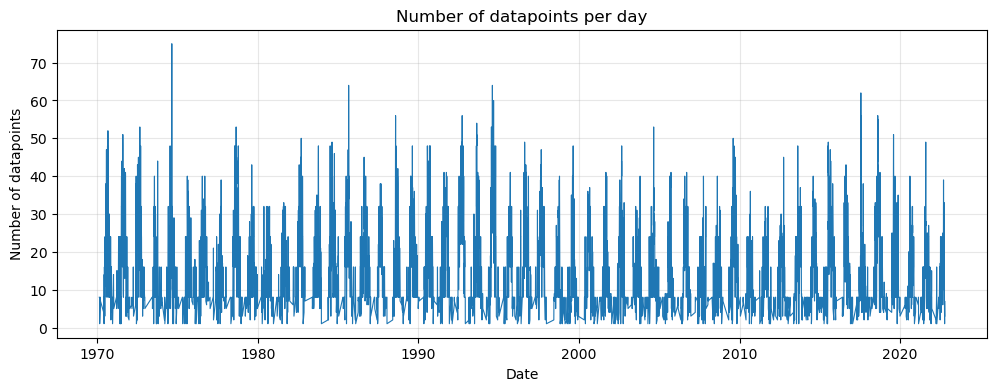

In [24]:
# 画图
plt.figure(figsize=(12, 4))
plt.plot(daily_counts.index, daily_counts.values, linewidth=0.8)

plt.xlabel('Date')
plt.ylabel('Number of datapoints')
plt.title('Number of datapoints per day')
plt.grid(True, alpha=0.3)

plt.show()

3.8 Calculate the climatology of datapoint counts as a function of day of year. The day of year is the sequential day number starting with day 1 on January 1st.

In [25]:
df_filtered['DOY'] = df_filtered['ISO_TIME'].dt.dayofyear     # 提取 Day of Year

# 统计每天的数据点总数，除年份数求均值
doy_counts = df_filtered.groupby('DOY').size() 
num_years = df_filtered['ISO_TIME'].dt.year.nunique()     # 计算覆盖的总年数
climatology = doy_counts / num_years

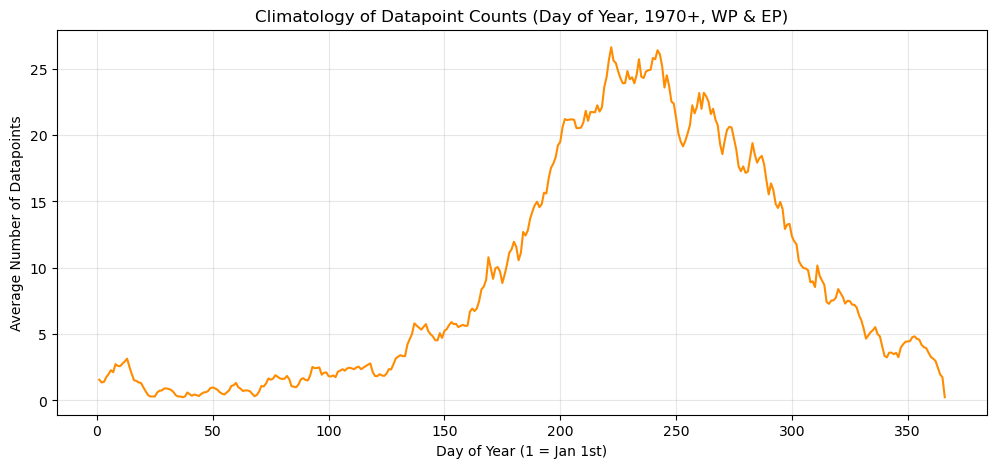

In [26]:
# 绘图
plt.figure(figsize=(12, 5))
plt.plot(climatology.index, climatology.values, color='darkorange', linewidth=1.5)

plt.title('Climatology of Datapoint Counts (Day of Year, 1970+, WP & EP)')
plt.xlabel('Day of Year (1 = Jan 1st)')
plt.ylabel('Average Number of Datapoints')
plt.grid(True, alpha=0.3)

plt.show()

3.9 Calculate the anomaly of daily counts from the climatology.

In [27]:
overall_mean = climatology.mean()     # 计算所有天数的总平均活跃度（整条曲线的基准线）

anomaly = climatology - overall_mean     # 异常值 = 每天的平均值 - 整体基准线

anomaly = anomaly.fillna(-overall_mean)     # 填补可能缺失的空白天为 0

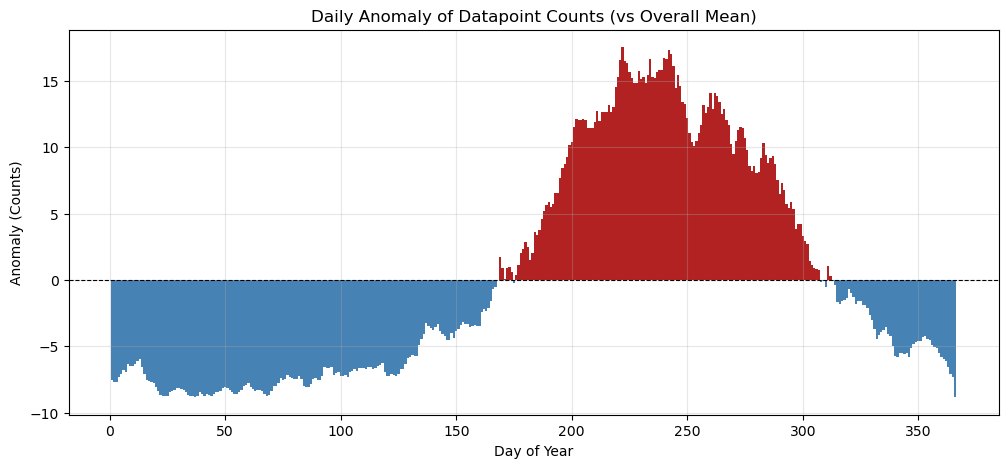

In [28]:
# 绘图
plt.figure(figsize=(12, 5))

colors = (anomaly > 0).map({True: 'firebrick', False: 'steelblue'})

plt.bar(anomaly.index, anomaly.values, color=colors, width=1.0)

plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.title('Daily Anomaly of Datapoint Counts (vs Overall Mean)')
plt.xlabel('Day of Year')
plt.ylabel('Anomaly (Counts)')
plt.grid(True, alpha=0.3)

plt.show()

3.10 Resample the anomaly timeseries at annual resolution and plot. So which years stand out as having anomalous hurricane activity?

In [29]:
df_time_indexed = df_filtered.set_index('ISO_TIME')

yearly_counts = df_time_indexed.resample('YE').size()     # 按年重采样，计算每年的数据点总数

yearly_counts.index = yearly_counts.index.year

mean_yearly_count = yearly_counts.mean()     # 计算平均每年的数据量

annual_anomaly = yearly_counts - mean_yearly_count     # 计算年度异常（实际 - 平均）

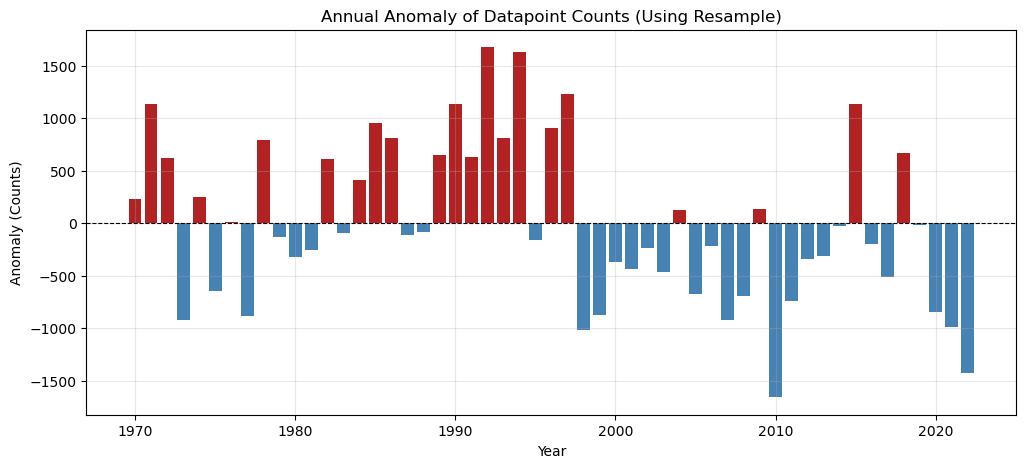

In [30]:
# 绘图
plt.figure(figsize=(12, 5))
colors = (annual_anomaly > 0).map({True: 'firebrick', False: 'steelblue'})
plt.bar(annual_anomaly.index, annual_anomaly.values, color=colors)

plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.title('Annual Anomaly of Datapoint Counts (Using Resample)')
plt.xlabel('Year')
plt.ylabel('Anomaly (Counts)')
plt.grid(True, alpha=0.3)

plt.show()

In [31]:
# 异常最高的几年
print("飓风活动最异常的年份 (Top 5):")
print(annual_anomaly.nlargest(5))

飓风活动最异常的年份 (Top 5):
ISO_TIME
1992    1674.603774
1994    1624.603774
1997    1228.603774
1990    1134.603774
2015    1132.603774
dtype: float64


### 4. Explore a data set

Browse the National Centers for Environmental Information (NCEI) or Advanced Global Atmospheric Gases Experiment (AGAGE) website. Search and download a data set you are interested in. You are also welcome to use data from your group in this problem set. But the data set should be in csv, XLS, or XLSX format, and have temporal information.

4.1 Load the csv, XLS, or XLSX file, and clean possible data points with missing values or bad quality.

选用了自己的全球内陆水体氧化亚氮排放通量数据集，文件为csv格式。

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [33]:
df = pd.read_csv(r'D:\SUST\ESE\Assignment\Assignment2\N2O_Samples_Global.csv')     # 读取数据

In [34]:
df['Date'] = pd.to_datetime(df['Year1'].astype(str) + '-' + df['Month1'].astype(str) + '-01', errors='coerce')     # 创建标准的时间列 

df_clean = df.dropna(subset=['N2O', 'LAT', 'LON', 'Date']).copy()     # 处理缺失值 (剔除 N2O 浓度、经纬度缺失的行)
df_clean = df_clean[df_clean['N2O'] >= 0]     # 去除异常值
df_clean = df_clean.drop_duplicates()     # 去除明显的重复记录

print(f"清洗前数据量: {len(df)} 行, 清洗后数据量: {len(df_clean)} 行")
print("清洗后的数据预览:")
display(df_clean.head())

清洗前数据量: 6356 行, 清洗后数据量: 5440 行
清洗后的数据预览:


,ACTYPE,Year1,Year2,Month1,Month2,LAT,LON,N2O,Date
0,Stream,2015,2015,12,12,29.616667,106.5,10.024,2015-12-01
1,Stream,2016,2016,12,12,29.616667,106.5,10.024,2016-12-01
2,Stream,2015,2015,3,3,29.616667,106.5,16.128,2015-03-01
3,Stream,2016,2016,3,3,29.616667,106.5,16.128,2016-03-01
4,Stream,2015,2015,7,7,29.616667,106.5,21.700,2015-07-01


4.2 Plot the time series of a certain variable.

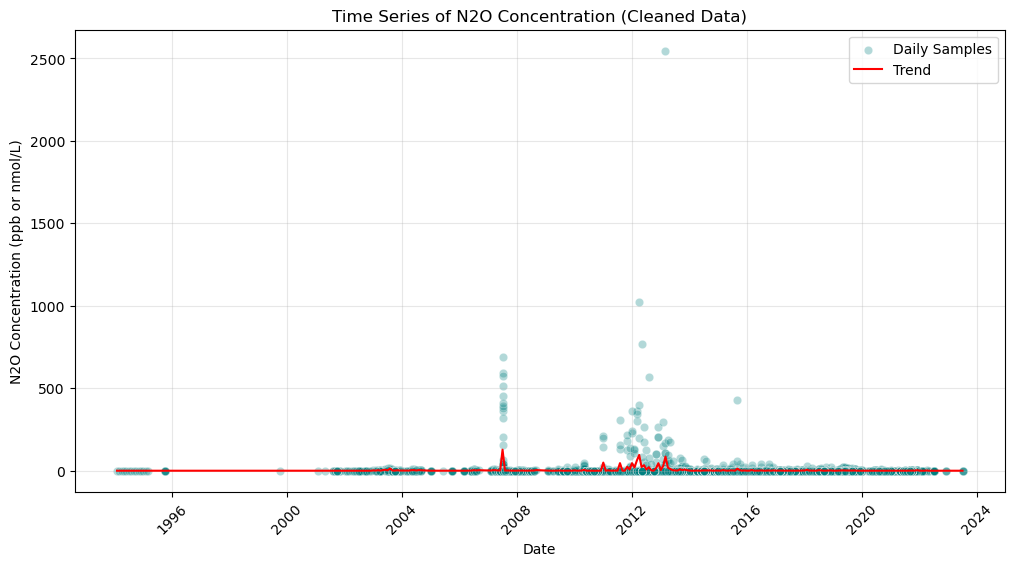

In [35]:
# 绘图 (N2O)
plt.figure(figsize=(12, 6))

sns.scatterplot(data=df_clean, x='Date', y='N2O', alpha=0.3, color='teal', label='Daily Samples')
sns.lineplot(data=df_clean, x='Date', y='N2O', color='red', label='Trend', errorbar=None)     # 趋势线

plt.title('Time Series of N2O Concentration (Cleaned Data)')
plt.xlabel('Date')
plt.ylabel('N2O Concentration (ppb or nmol/L)')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

4.3 Conduct at least 5 simple statistical checks with the variable, and report your findings.

In [36]:
# 检验 1: 描述性统计 (均值、标准差、极值)
stats = df_clean['N2O'].describe()
print("\n1. 描述性统计 (N2O浓度):")
print(stats)


1. 描述性统计 (N2O浓度):
count    5440.000000
mean        4.526910
std        48.465317
min         0.000000
25%         0.057543
50%         0.226584
75%         0.690033
max      2546.652000
Name: N2O, dtype: float64


In [37]:
# 检验 2: 按水体类型 (ACTYPE) 进行分组比较
print("\n2. 不同水体类型 (ACTYPE) 的 N2O 平均浓度对比:")
print(df_clean.groupby('ACTYPE')['N2O'].mean().sort_values(ascending=False))


2. 不同水体类型 (ACTYPE) 的 N2O 平均浓度对比:
ACTYPE
Lake         13.586964
River         6.655377
Stream        2.190805
Pond          0.874982
Reservoir     0.854010
Marsh         0.018387
Name: N2O, dtype: float64


In [38]:
# 检验 3: 缺失值统计 (说明数据质量)
print("\n3. 原始数据缺失值占比分析 (Bad Quality Check):")
print(df.isnull().sum() / len(df) * 100)


3. 原始数据缺失值占比分析 (Bad Quality Check):
ACTYPE    0.0
Year1     0.0
Year2     0.0
Month1    0.0
Month2    0.0
LAT       0.0
LON       0.0
N2O       0.0
Date      0.0
dtype: float64


In [39]:
# 检验 4: 正态性检验 (Shapiro-Wilk 检验)
from scipy.stats import shapiro
sample_data = df_clean['N2O'].sample(n=min(500, len(df_clean)), random_state=42)
stat, p_value = shapiro(sample_data)
print(f"\n4. 正态性检验 (Shapiro-Wilk): p-value = {p_value:.4f}")
if p_value < 0.05:
    print("   -> 结论: N2O 浓度数据不符合正态分布 (显著偏态)。")
else:
    print("   -> 结论: N2O 浓度数据符合正态分布。")


4. 正态性检验 (Shapiro-Wilk): p-value = 0.0000
   -> 结论: N2O 浓度数据不符合正态分布 (显著偏态)。


In [40]:
# 检验 5: 纬度与 N2O 的相关性检验 (Pearson 相关系数)
from scipy.stats import pearsonr
corr, p_val_corr = pearsonr(df_clean['LAT'], df_clean['N2O'])
print(f"\n5. 纬度 (LAT) 与 N2O 浓度的 Pearson 相关性: r = {corr:.3f}, p-value = {p_val_corr:.4f}")
if p_val_corr < 0.05:
    print("   -> 结论: 纬度与 N2O 浓度具有显著相关性。")
else:
    print("   -> 结论: 纬度与 N2O 浓度无显著相关性。")


5. 纬度 (LAT) 与 N2O 浓度的 Pearson 相关性: r = 0.012, p-value = 0.3850
   -> 结论: 纬度与 N2O 浓度无显著相关性。


1. 描述性统计与分布特征：清洗后共有 5,440 个有效数据点。N2O 浓度呈现极强的右偏态（正偏态）。均值（4.53）远大于中位数（0.23），且最大值极高（高达 2546.65），而 75% 的数据都低于 0.69。标准差（48.47）远大于均值，说明数据存在极端的离群值（Outliers）。
2. 不同水体类型的 N2O 平均浓度对比：水体类型（ACTYPE）对 N2O 浓度有显著影响。湖泊（Lake） 的平均 N2O 浓度最高（13.59），其次是河流（River，6.66）、溪流（Stream，2.19）。而池塘（Pond）、水库（Reservoir）和沼泽（Marsh）的平均浓度较低（均低于 1）。
3. 原始数据缺失值分析（数据质量检查）：原始数据集中所有核心列（水体类型、时间、经纬度、N2O浓度）的缺失值比例均为 0.0%。
4. 正态性检验 (Shapiro-Wilk Test)：在统计学上拒绝了正态分布的零假设。结合描述性统计中的极大均值差异，证实 N2O 浓度数据不符合正态分布。  
5. 纬度与 N2O 浓度的相关性检验 (Pearson Correlation)：在 95% 的置信水平下，纬度（LAT）与水体 N2O 浓度不存在显著的线性相关性。这说明 N2O 的排放浓度更多受局地环境因素（如水体类型、温度、溶解氧、氮负荷）的驱动，而非简单的全球性纬度气候梯度规律。